In [1]:
#import some basic classes
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.util as cutil
import matplotlib.pyplot as plt
import statsmodels.api as sm
from tqdm import tqdm
from scipy import stats
#my own classes
import sys
sys.path.append("/Users/michelefilippucci/Prog/github/blocktrack/lib")
import blocktoolbox as BT
sys.path.append("/Users/michelefilippucci/Prog/github/AtmBlockPy/lib")
import BlockPlots as BP

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [2]:
%cd /Users/michelefilippucci/Data/ERA5
!ls

/Users/michelefilippucci/Data/ERA5
ERA5_2.5x2.5_zg500_daily_1940-2024.nc
ERA5_clim_snowc_0.1x0.1_1980-2000.nc
ERA5_geopotential_day_2.5x2.5_500hPa_1950-2021.nc
ERA5_northem_2.5x2.5_zg500_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg500_daily_1950-1960.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_1950-1960.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1950-1960.nc
ERA5_northem_2.5x2.5_zg_daily_1959-2021.nc
ERA5_ta_mon_r144x73_19790101-20191231.nc
ERA5_ymonmean_snowc_0.1x0.1_1980-2000.nc
dictionaries
prepare_dataset.ipynb
snow_cover_ERA5_0.1x0.1_1980-2000.nc
ta
ua
va


In [3]:

#coordinates of the point where we look for blocking
plon,plat=-35.0,70.0 #Greenland
#plon,plat=10.0,55.0 #Europe
#plon,plat=-10.0,55.0 #Western Europe

fn = 'ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_1950-1960.nc'

#loading dataset
ds = xr.open_dataset(fn)
lons = ds['lon']
lats = ds['lat']
zg = ds['zg'].values
DAV_bool = ds['DAV_tracked'].values
#dimensions of the needed fields.
lonHotSpot = BT.GetIndex(ds,"lon",str(plon))
latHotSpot = BT.GetIndex(ds,"lat",str(plat)) 
ds.close()

In [4]:

dic_for_filtering = np.load('dictionaries/ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_1950-1960_DIC.npy',allow_pickle=True) #original

#print(dic_for_filtering)

#create a list of indexes
indexes = []
timings = []
for t in tqdm(range(len(ds["time"].values))):
    for l in np.unique(DAV_bool[t,:,:]):
        #print(dic_for_filtering[l-1]['distance_traveled'])
        #print(DAV_bool[t,latHotSpot,lonHotSpot])
        if l!=0 and np.all(l==DAV_bool[t:t+4,latHotSpot,lonHotSpot]) and dic_for_filtering[l-1]['avg_dist_traveled']<600 and not l in indexes: #and dic_for_filtering[l-1]['distance_traveled']>1500#DAV_bool[t-1,:,:]:
            #print(np.mean(dic_for_filtering[l]['track'][0]))
            indexes.append(l)
            timings.append(t)
print(len(indexes))

100%|████████████████████████████████████████████████████████████████| 4018/4018 [00:00<00:00, 25705.16it/s]

23


In [5]:
"""
A list of trajectories is then produced
"""
dic = []
for i,l in tqdm(enumerate(indexes)):
    dic.append({})
    dic[i]['track'] = dic_for_filtering[l-1]['track']
    dic[i]['area'] = dic_for_filtering[l-1]['avg_area']
    dic[i]['date'] = dic_for_filtering[l-1]['date']
    dic[i]['avg_dist_traveled'] = dic_for_filtering[l-1]['avg_dist_traveled']

23it [00:00, 227521.21it/s]


In [6]:
for i,event in enumerate(dic):
    if event['avg_dist_traveled'] > 600:
        print(event['date'])
        print(indexes[i])
        

/Users/michelefilippucci/miniconda3/envs/blocktoolbox_env/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/Users/michelefilippucci/miniconda3/envs/blocktoolbox_env/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:475: UserWarning: The .ylabels_left attribute is deprecated. Please use .left_labels to toggle visibility instead.
  warnings.warn('The .ylabels_left attribute is deprecated. Please '


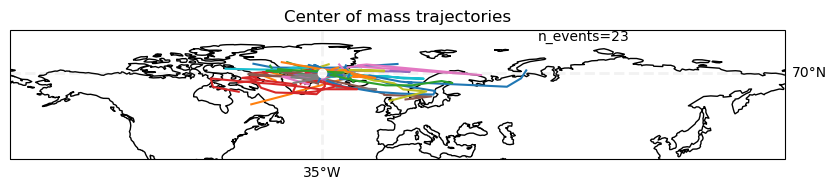

In [7]:
import matplotlib.ticker as mticker

plt.figure(figsize=(10,4))

#dic =np.load("/Users/michelefilippucci/Prog/summer_greenland_block/data_tmp/dic_"+str(plon)+"-"+str(plat)+".npy",allow_pickle=True)
xs=[]
ys=[]
areas = []
for i in range(len(indexes)):
    #if 1959 == int(str(ds["time"].values[timings[i]])[0:4]):
    xs.append(dic[i]['track'][0])
    ys.append(dic[i]['track'][1])
    areas.append(dic[i]['area'])
output = "/home/mich/plots/POSTER/snapshots/trajectories_"+str(plon)+"-"+str(plat)+".png"
#plot the trajectories to see what you are looking at
mapcrs = ccrs.PlateCarree()
datacrs = ccrs.PlateCarree()
extent =[-180,+180,30,90]
ax = plt.subplot(111, projection=mapcrs)
ax.set_extent(extent, datacrs)
ax.coastlines()
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=2, color='gray', alpha=0.1, linestyle='--')
gl.xlocator = mticker.FixedLocator([plon])
gl.ylocator = mticker.FixedLocator([plat])
gl.xlabels_top = False
gl.ylabels_left = False
for i in range(len(xs)):
    cm = plt.plot(ys[i],xs[i],transform=datacrs)
plt.text(65, 85, 'n_events='+str(len(xs)), fontsize = 10)
plt.plot(lons[lonHotSpot],lats[latHotSpot],'ow',transform=datacrs)#transorm=datacrs)
plt.title('Center of mass trajectories', loc = 'center')


#plt.show()
#plt.savefig(output,bbox_inches='tight',dpi=400)
plt.savefig('/Users/michelefilippucci/PLOTS/blocking poster/tracks.png',dpi=300)


In [8]:
xs=[]
ys=[]
areas = []
for i in range(len(indexes)):
    xs.append(dic[i]['track'][1])
    ys.append(dic[i]['track'][0])
    areas.append(dic[i]['area'])
#we want to store:
#-event label: dictionary key*
#-month
#-year
#-avg area in lifetime
#-initial distance from point
#-final distance from point 
#-duration
feature_dictionaries = []
for i,l in tqdm(enumerate(indexes)):
    event = {"label":l,
                "month":str(ds["time"].values[timings[i]])[5:7],
                "year":str(ds["time"].values[timings[i]])[0:4],
                "avg_area":np.mean(areas[i]),
                "duration":len(xs[i]),
                "initial_distance":((plon-xs[i][0])**2+(plat-ys[i][0])**2)**0.5,
                "final_distance":((plon-xs[i][-1])**2+(plat-ys[i][-1])**2)**0.5,
                "displacement_lon":plon-xs[i][0],
                "displacement_lat":plat-ys[i][0]
                }
    #print(event["displacement_lon"])
    feature_dictionaries.append(event)
    #np.save("/Users/michelefilippucci/Prog/summer_greenland_block/data_tmp/feature_dictionaries_"+str(plon)+"-"+str(plat)+".npy",feature_dictionaries)
    #print(event["duration"])


23it [00:00, 31199.54it/s]


In [9]:
def Hist_Matrix_Season(feature_dictionaries,quantity,bin_size_y=10,year_range=(1943,2024)):
    y_array = np.arange(year_range[0],year_range[1]-bin_size_y,bin_size_y)
    seasons_mapping = {
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Autumn",
    10: "Autumn",
    11: "Autumn",
    12: "Winter"
    }
    x_array = ("Winter","Spring","Summer","Autumn")
    arr = np.zeros((len(y_array),len(x_array)))
    arr_err = np.zeros((len(y_array),len(x_array)))
    for i,x in enumerate(x_array):
        list_err = []
        for j,y in enumerate(y_array):
            count = 0
            for item in feature_dictionaries:
                if int(item["year"]) >= y and int(item["year"]) < y + bin_size_y and seasons_mapping[int(item["month"])] == x:
                    count += 1
                    try:
                        arr[j,i] += item[quantity]
                        list_err.append(item[quantity])
                    except:
                        arr[j,i] += 1 #the number of events case
            if quantity != "number_of_events":
                arr[j,i] = arr[j,i]/count
        if quantity != "number_of_events":
            for j,y in enumerate(y_array):
                arr_err[j,i] = np.std(list_err)
        if quantity == "number_of_events":
            for i,x in enumerate(x_array):
                for j,y in enumerate(y_array):
                    arr_err[j,i]=np.std(arr[:,i])
    return x_array,y_array,arr,arr_err

def Hist_Matrix(feature_dictionaries,quantity,bin_size_x="season",bin_size_y=5,year_range=(1943,2023)):
    y_array = np.arange(year_range[0],year_range[1]-bin_size_y,bin_size_y)
    x_array = np.arange(0,12,bin_size_x)
    arr = np.zeros((len(y_array),len(x_array)))
    list_err = []
    arr_err = np.zeros((len(y_array),len(x_array)))
    for i,x in enumerate(x_array):
        for j,y in enumerate(y_array):
            count = 0
            for item in feature_dictionaries:
                if int(item["year"]) >= y and int(item["year"]) < y + bin_size_y and int(item["month"]) >= x and int(item["month"]) < x + bin_size_x:
                    count += 1
                    try:
                        arr[j,i] += item[quantity]
                        list_err.append(item[quantity])
                    except:
                        arr[j,i] += 1 #the number of events case
            if quantity != "number_of_events":
                arr[j,i] = arr[j,i]/count
                arr_err[j,i] = np.std(list_err)
            if quantity == "number_of_events":
                for i,x in enumerate(x_array):
                    for j,y in enumerate(y_array):
                        arr_err[j,i]=np.std(arr[j,:])
                        
    return x_array,y_array,arr


def heatmap(data, row_labels, col_labels, ax = None,
            cbar_kw = {}, cbarlabel = "",ylab=True, **kwargs):
    """
    Create a heatmap from a numpy array and two lists of labels.

    Parameters
    ----------
    data
        A 2D numpy array of shape (M, N).
    row_labels
        A list or array of length M with the labels for the rows.
    col_labels
        A list or array of length N with the labels for the columns.
    ax
        A `matplotlib.axes.Axes` instance to which the heatmap is plotted.  If
        not provided, use current axes or create a new one.  Optional.
    cbar_kw
        A dictionary with arguments to `matplotlib.Figure.colorbar`.  Optional.
    cbarlabel
        The label for the colorbar.  Optional.
    **kwargs
        All other arguments are forwarded to `imshow`.
    """

    if not ax:
      ax = plt.gca()

    if quantity == 'displacement_lon' or quantity == 'displacement_lat':
        vmin=-np.max(np.abs(data))
        vmax=np.max(np.abs(data))
        colormap = 'coolwarm'
    else:
        vmin=np.min(np.abs(data)) 
        vmax=np.max(np.abs(data))
        colormap = 'viridis'

    # Plot the heatmap
    im = ax.imshow(data,**kwargs,cmap=colormap,
                  vmin=vmin, vmax=vmax)
                  #vmin=-np.max(np.abs(data)), vmax=np.max(np.abs(data)))

    # Create colorbar
    cbar = ax.figure.colorbar(im, ax = ax,aspect =20 ,fraction=0.05, pad=0.05,label = cbarlabel,orientation = 'horizontal',**cbar_kw)
    # Show all ticks and label them with the respective list entries.
    ax.set_xticks(np.arange(data.shape[1]))
    ax.set_xticklabels(col_labels,)
    if ylab == True:
        ax.set_yticks(np.arange(data.shape[0]))
        ax.set_yticklabels(row_labels)
        # Rotate the tick labels and set their alignment.
        plt.setp(ax.get_yticklabels(), rotation = -30, ha = "right",
                rotation_mode = "anchor")
        ax.set_yticks(np.arange(data.shape[0] + 1) - 0.5, minor = True)

    # Let the horizontal axes labeling appear on top.
    ax.tick_params(top = True, bottom = False,
                   labeltop = True, labelbottom = False)
    # Turn spines off and create white grid.
    ax.spines[:].set_visible(False)
    ax.set_xticks(np.arange(data.shape[1] + 1) - 0.5, minor = True)
    ax.grid(which = "minor", color = "w", linestyle = '-', linewidth = 3)
    ax.tick_params(which =  "minor", bottom = False, left = False)

    return im, cbar


/var/folders/1t/z1lq9tg16ylg486l4nrf2fgr0000gn/T/ipykernel_66481/4184428701.py:57: RuntimeWarning: divide by zero encountered in divide
  model = sm.WLS(y_fit, sm.add_constant(x_fit), weights=1.0 / (y_fit_err ** 2))
/Users/michelefilippucci/miniconda3/envs/blocktoolbox_env/lib/python3.11/site-packages/statsmodels/regression/linear_model.py:774: RuntimeWarning: invalid value encountered in multiply
  return np.sqrt(self.weights)[:, None] * x
/Users/michelefilippucci/miniconda3/envs/blocktoolbox_env/lib/python3.11/site-packages/statsmodels/regression/linear_model.py:772: RuntimeWarning: invalid value encountered in multiply
  return x * np.sqrt(self.weights)


[<Axes: > <Axes: > <Axes: > <Axes: > <Axes: >]


LinAlgError: SVD did not converge

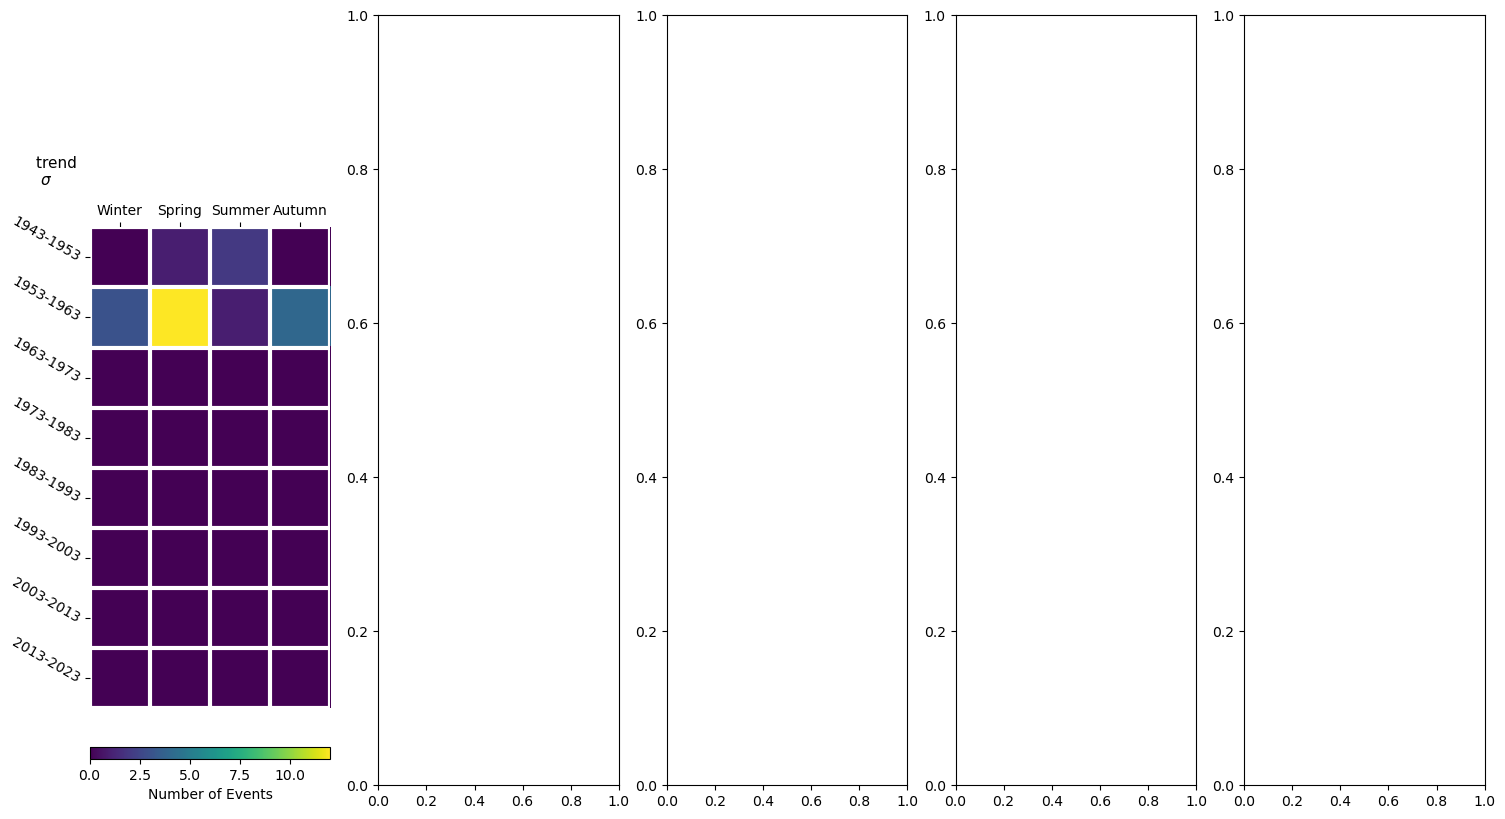

In [10]:
plt.rcParams['figure.figsize'] = [18,10]

bin_dim = 10

quantity = "number_of_events"
cbar_lab_dic={}
cbar_lab_dic["number_of_events"] = 'Number of Events'
cbar_lab_dic["avg_area"] = 'Area ($km^2$)'
cbar_lab_dic["duration"] = 'Persistence (days)'
cbar_lab_dic["displacement_lon"] = 'Longitudinal Displacement (°W)'
cbar_lab_dic["displacement_lat"] = 'Latitudinal Displacement (°N)'

fig, axes = plt.subplots(nrows=1,ncols=5)

print(axes)

flag = True

for i,quantity in enumerate(['number_of_events','avg_area','duration','displacement_lon','displacement_lat']):
    if i>0:
        flag = True
    x,y,data,data_err = Hist_Matrix_Season(feature_dictionaries=feature_dictionaries,
                            bin_size_y=bin_dim,
                        quantity=quantity,
                        )
    #print(i)
    # Labels
    xlabs = ["Winter","Spring","Summer","Autumn"]
    """
    xlabs = []
    for month in x:
        xlabs.append(str(month+1))
    """
    ylabs = []
    if i > 0:
        for year in y:
            ylabs.append('')

    else:
        for year in y:
            ylabs.append(str(year)+"-"+str(year+bin_dim))

    heatmap(data, row_labels = ylabs, col_labels = xlabs,
            ax = axes[i],ylab = flag, cbarlabel = cbar_lab_dic[quantity])

    
    if i == 0:
        axes[i].text(-0.4 -1,-1.2,'trend \n $\sigma$',fontsize=11)
    if i >= 0:
        for s in range(len(xlabs)):
            #linear regression
            x_fit = np.array(range(data.shape[0]))
            y_fit = data[:,s]
            y_fit_err = data[:,s]# Associated errors

            # Fit linear regression model with errors
            model = sm.WLS(y_fit, sm.add_constant(x_fit), weights=1.0 / (y_fit_err ** 2))
            result = model.fit()

            #Print the regression summary
            #print(result.summary())
            #print(result.params)
            pend = result.params[1]
            pend_err = result.bse[1]
            if i == 1:
                corr = 1e5
                pend = pend/corr
                pend_err = pend_err/corr
            axes[i].text(s,-1.2,"%.2f" % pend + '\n' + "%.2f" % pend_err,fontsize=11,horizontalalignment='center')
        units_fontsize = 10
        if i == 0:
            axes[i].text(s-1,-2,'[#events/decade]',fontsize=units_fontsize,horizontalalignment='left')
        if i == 1:
            axes[i].text(s-1,-2,'[$10^5\ km^2$/decade]',fontsize=units_fontsize,horizontalalignment='left')
        if i == 2:
            axes[i].text(s-1,-2,'[days/decade]',fontsize=units_fontsize,horizontalalignment='left')
        if i == 3:
            axes[i].text(s-1,-2,'[°W/decade]',fontsize=units_fontsize,horizontalalignment='left')
        if i == 4:
            axes[i].text(s-1,-2,'[°N/decade]',fontsize=units_fontsize,horizontalalignment='left')
        
    '''
    heatmap(data, row_labels = ylabs, col_labels = xlabs,
            ax = ax, cmap = "coolwarm", cbarlabel = "latitudinal displacement (°N)")
    '''

#plt.title("Greenland",fontsize = 14)
#plt.tight_layout()
plt.savefig('/Users/michelefilippucci/PLOTS/blocking poster/dyn_analysis.png',dpi=300)


# 